# Gecikme modeli canlıda hâlâ aynı riski mi ölçüyor?

Model eşik 0,30 ile siparişlere alarm veriyor. Yeni dönemde yoğun vardiya payı artıyor. Son 600 siparişin gecikme durumu henüz kesin değil. Ekibin bir kısmı etiket boşsa gecikme yok sayarak başarı raporu hazırlamak istiyor.

Karar: Alarm yükü ve olgun etiketler model müdahalesini destekliyor mu? İlk kontrol hangisi?

Veriler sentetiktir. Her senaryo sabit tohumla aynı veriyi yeniden oluşturur. CSV dosyaları örnek çıktıdır. Bir CSV’yi değiştirmen bu defterin verisini otomatik değiştirmez.


In [1]:
import numpy as np
import pandas as pd
from scipy import stats
from scipy.special import expit
import matplotlib.pyplot as plt

BLUE, ORANGE, GREEN, GRAY = '#2457ad', '#ac452c', '#197254', '#64748b'
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'axes.axisbelow': True, 'grid.alpha': .19})

def table(frame, title):
    return dict(title=title, columns=frame.columns.tolist(),
                rows=frame.astype(object).where(frame.notna(), None).values.tolist())

def monitoring(scenario='default'):
    rng=np.random.default_rng(72105)
    n=2400
    group_old=(rng.random(n)<.25).astype(int)
    group_new=(rng.random(n)<(.60 if scenario=='shift' else .25)).astype(int)
    x_old=rng.normal(0,1,n)
    x_new=rng.normal(0,1,n)
    p_old=expit(-2.40+1.15*group_old+.85*x_old)
    p_new=expit(-2.40+1.15*group_new+.85*x_new)
    true_new=expit(-2.40+1.15*group_new+.85*x_new+(.7*group_new if scenario=='shift' else 0))
    y_old=(rng.random(n)<p_old).astype(int)
    y_new=(rng.random(n)<true_new).astype(int)
    mature=np.arange(n)<1800
    threshold=.30
    raw=pd.DataFrame({'Pencere':np.repeat(['Referans','Yeni'],n),'Gözlem':np.tile(np.arange(1,n+1),2),
                      'Yoğun vardiya':np.r_[group_old,group_new],'Sabit risk skoru':np.r_[p_old,p_new],
                      'Etiket olgun':np.r_[np.ones(n,dtype=bool),mature],
                      'Gecikme':np.r_[y_old,np.where(mature,y_new,np.nan)]})
    summary=[]
    calibration=[]
    for label,frame in raw.groupby('Pencere',sort=False):
        observed=frame[frame['Etiket olgun']]
        for group in ['Tümü',0,1]:
            f=observed if group=='Tümü' else observed[observed['Yoğun vardiya']==group]
            s=f['Sabit risk skoru'].to_numpy()
            y=f.Gecikme.to_numpy()
            a=s>=threshold
            fp=int(np.sum(a & (y==0)))
            fn=int(np.sum(~a & (y==1)))
            summary.append([label,'Tümü' if group=='Tümü' else ('Yoğun' if group==1 else 'Normal'),len(f),
                            s.mean(),y.mean(),np.mean((s-y)**2),int(a.sum()),fp,fn,(fp+8*fn)*1000/len(f)])
        s=observed['Sabit risk skoru'].to_numpy()
        y=observed.Gecikme.to_numpy()
        boundaries=[0,.1,.2,.3,.5,1.01]
        for low,high in zip(boundaries[:-1],boundaries[1:]):
            member=(s>=low)&(s<high)
            if member.sum()>0:
                calibration.append([label,low,high,int(member.sum()),s[member].mean(),y[member].mean()])
    summary=pd.DataFrame(summary,columns=['Pencere','Vardiya','Etiketli n','Ortalama skor','Gözlenen oran','Brier','Alarm','Yanlış alarm','Kaçırma','Kayıp puanı / 1.000'])
    calibration=pd.DataFrame(calibration,columns=['Pencere','Skor altı','Skor üstü','n','Ortalama skor','Gözlenen oran'])
    fig,ax=plt.subplots(figsize=(7.2,4.4),layout='constrained')
    ax.plot([0,.8],[0,.8],'--',color=GRAY,label='Skor = gerçekleşme')
    for (label,frame),color in zip(calibration.groupby('Pencere',sort=False),[BLUE,ORANGE]):
        ax.plot(frame['Ortalama skor'],frame['Gözlenen oran'],'o-',color=color,label=label)
    ax.set(xlim=(0,.8),ylim=(0,.8),xlabel='Ortalama tahmin',ylabel='Gerçek gecikme oranı',
           title='Sabit skorun anlamı değişti mi?')
    ax.legend(fontsize=9)
    fig2,ax2=plt.subplots(figsize=(8.6,3.7),layout='constrained')
    latest=summary[(summary.Pencere=='Yeni') & (summary.Vardiya!='Tümü')]
    x=np.arange(len(latest))
    ax2.bar(x-.17,latest['Ortalama skor']*100,.34,color=BLUE,label='Tahmin ortalaması')
    ax2.bar(x+.17,latest['Gözlenen oran']*100,.34,color=ORANGE,label='Gerçekleşen')
    ax2.set(xticks=x,xticklabels=latest.Vardiya,ylabel='Gecikme · %',title='Yeni dönemin olgun etiketleri, vardiyaya göre')
    ax2.legend()
    alert_load=(p_new>=threshold).mean()
    current=summary[(summary.Pencere=='Yeni') & (summary.Vardiya=='Tümü')].iloc[0]
    return dict(metrics={'Yeni kayıt':n,'Olgun etiket':int(mature.sum()),'Bekleyen etiket':int((~mature).sum()),
                         'Tüm yeni kayıt · alarm %':alert_load*100,'Olgun etiket · Brier':current.Brier},
        tables=[table(summary,'Sabit 0,30 eşik: olgun kayıtlar ve vardiyalar'),table(calibration,'Güvenilirlik grafiğinin sayı tablosu')],
        figures=[('Her nokta sabit skor aralığındaki ortalama risk ve gerçekleşme oranıdır. Kutuların n değerlerini birlikte oku.',fig),
                 ('Ortalama uyum toplamda iyi görünse bile yoğun vardiyada gecikme riski düşük tahmin edilebilir.',fig2)],
        frames={'izleme_skorlari':raw,'vardiya_izleme':summary},
        steps=['Etiketi olgunlaşmamış 600 kaydı gecikmedi diye yazma. Veri karması ve alarm hacmini tüm yeni kayıtlarda ölç; doğruluğu yalnız ortak takip süresi tamamlananlarda değerlendir.',
               'Tahmin ve gerçekleşmeyi aynı sabit skor kutularında ve aynı vardiya kırılımında karşılaştır. Brier ortalama (skor−sonuç)² değeridir.',
               'Sabit eşikte 1 yanlış alarm ve 8 kaçırma puanı varsay. İş yükü, hata maliyeti ve veri kaymasını ayrı ayrı araştır.'],
        decision='Yoğun vardiyada hem pay değişimi hem risk artışı var. İlk adım etiket ve vardiya kaydını doğrulamak, ardından ayrı bir zaman kesiminde kalibrasyon ve eşik seçimini sınamak.' if scenario=='shift' else 'Bu öğretim örneğinde yeni pencere aynı mekanizmayla üretilir. Örneklem dalgalanması nedeniyle küçük farklar olabilir. Etiket olgunluğunu ve alarm yükünü izlemeye devam et.',
        limit='Skorlar sentetik ve donmuş. Vardiya karşılaştırması açıklayıcıdır, ayrımcılık ya da nedensellik testi değildir. Tüm pencere için performans, son 600 etiket tamamlanmadan bilinmez. Kayıp puanları örnek varsayımdır, para değildir.',
        diagnostics={'mature':mature.sum(),'total':n,'threshold':threshold,'share_old':group_old.mean(),'share_new':group_new.mean(),
                     'late_n':current['Etiketli n'],'fp':current['Yanlış alarm'],'fn':current['Kaçırma']},
        focus=[['Olgunluk','1.800 / 2.400','600 etiket bekliyor'],['Yoğun vardiya',f'%{group_old.mean()*100:.1f} → %{group_new.mean()*100:.1f}','Karma değişimi'],['Operasyon',f'%{alert_load*100:.1f} alarm','Kapasiteyle karşılaştır']])


def print_result(result):
    for name, value in result['metrics'].items():
        print(f"{name}: {value}")
    print()
    for t in result['tables']:
        print(t['title'])
        print(pd.DataFrame(t['rows'], columns=t['columns']).to_string(index=False))
        print()
    print('Karar:', result['decision'])
    print('Koşullar:', result['limit'])


## Sabit veri mekanizması

Yeni dönemde 253 alarm var. 2.400 kaydın 1.800 etiketi olgun. Operasyonun toplam yeni alarm yükü yüzde kaç?


Yeni kayıt: 2400
Olgun etiket: 1800
Bekleyen etiket: 600
Tüm yeni kayıt · alarm %: 10.541666666666668
Olgun etiket · Brier: 0.10216711015189807

Sabit 0,30 eşik: olgun kayıtlar ve vardiyalar
 Pencere Vardiya  Etiketli n  Ortalama skor  Gözlenen oran    Brier  Alarm  Yanlış alarm  Kaçırma  Kayıp puanı / 1.000
Referans    Tümü        2400       0.143248       0.140833 0.109513    272           170      236           857.500000
Referans  Normal        1795       0.106469       0.110306 0.092473     71            48      175           806.685237
Referans   Yoğun         605       0.252369       0.231405 0.160068    201           122       61          1008.264463
    Yeni    Tümü        1800       0.143574       0.131667 0.102167    192           118      163           790.000000
    Yeni  Normal        1378       0.109949       0.103048 0.086390     60            38      120           724.238026
    Yeni   Yoğun         422       0.253371       0.225118 0.153686    132            80       

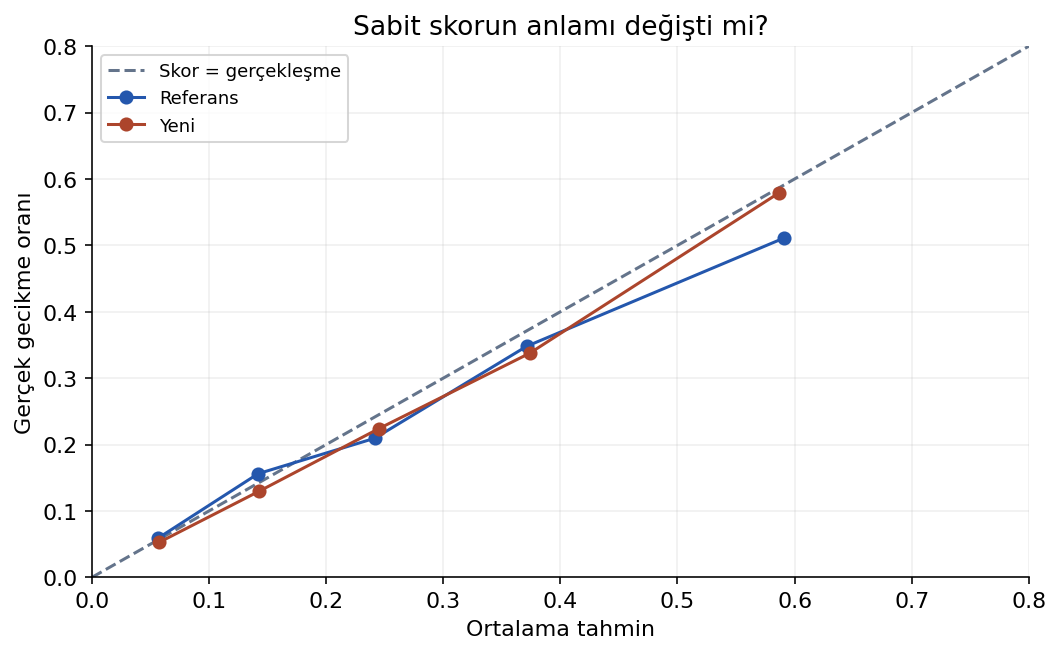

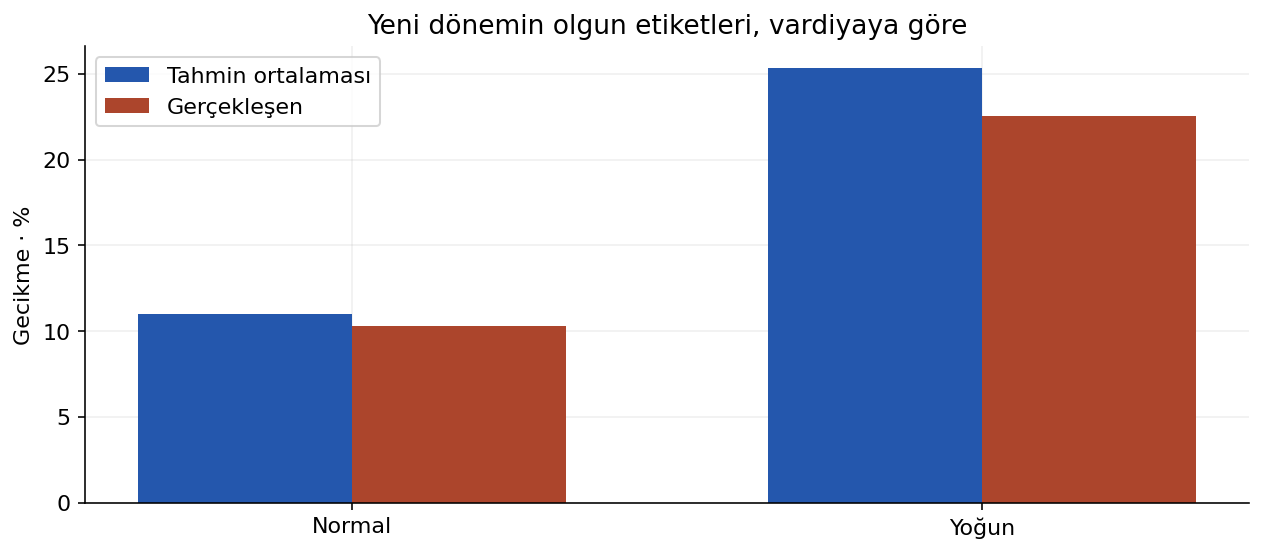

In [2]:
result = monitoring('default')
print_result(result)
plt.show()


## Yoğun vardiya payı ve gecikme riski artıyor

Yeni dönemde 515 alarm var. 2.400 kaydın 1.800 etiketi olgun. Operasyonun toplam yeni alarm yükü yüzde kaç?


Yeni kayıt: 2400
Olgun etiket: 1800
Bekleyen etiket: 600
Tüm yeni kayıt · alarm %: 21.458333333333332
Olgun etiket · Brier: 0.16467952937841082

Sabit 0,30 eşik: olgun kayıtlar ve vardiyalar
 Pencere Vardiya  Etiketli n  Ortalama skor  Gözlenen oran    Brier  Alarm  Yanlış alarm  Kaçırma  Kayıp puanı / 1.000
Referans    Tümü        2400       0.143248       0.140833 0.109513    272           170      236           857.500000
Referans  Normal        1795       0.106469       0.110306 0.092473     71            48      175           806.685237
Referans   Yoğun         605       0.252369       0.231405 0.160068    201           122       61          1008.264463
    Yeni    Tümü        1800       0.198791       0.270000 0.164680    390           165      261          1251.666667
    Yeni  Normal         724       0.108135       0.106354 0.089236     31            21       67           769.337017
    Yeni   Yoğun        1076       0.259790       0.380112 0.215442    359           144      1

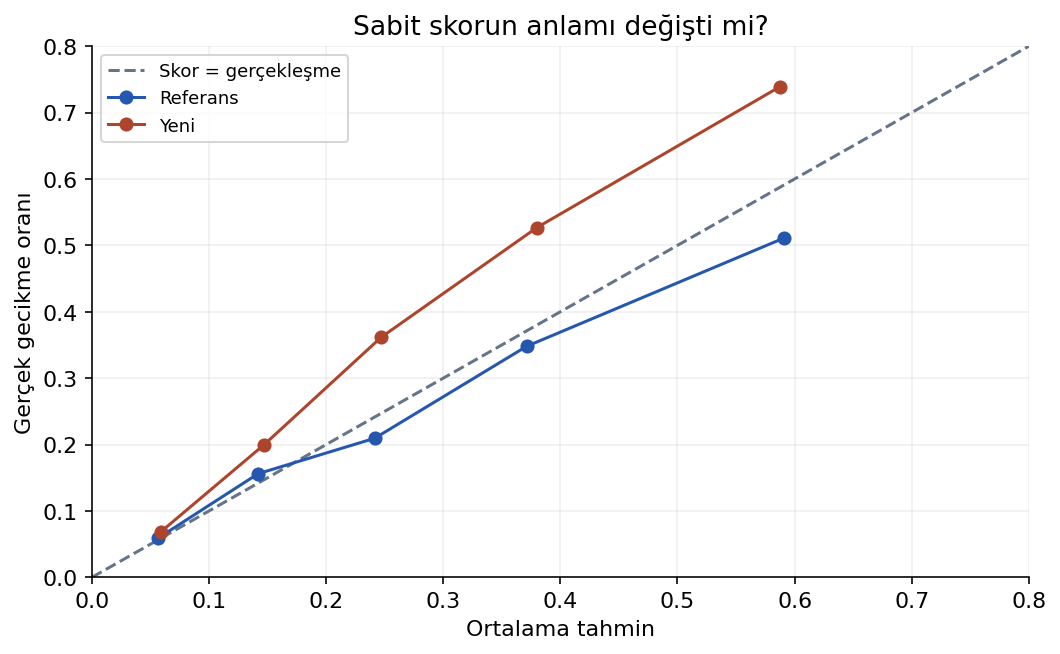

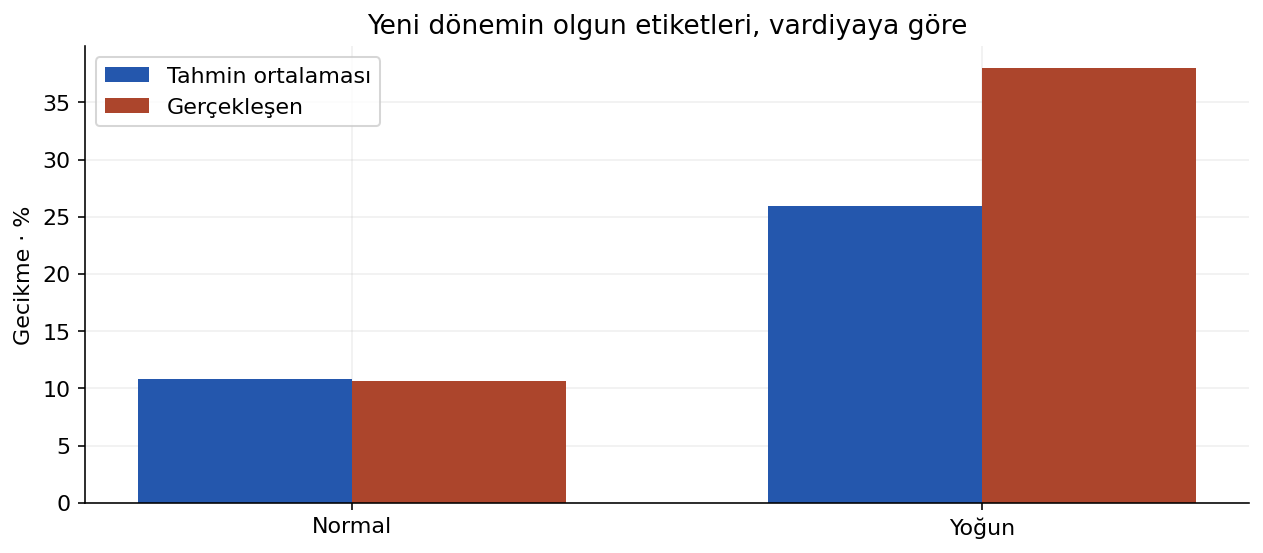

In [3]:
result = monitoring('shift')
print_result(result)
plt.show()


## Karar notu

Karma ve risk değişimi olan senaryoda neden “model bozuldu, hemen yeniden eğit” demek yerine önce hangi üç kontrolü yapacağını yaz.

- Olgunluk için zaman kesimini ve paydaları doğru yaz.
- Yoğun vardiyadaki risk uyumu ile tüm alarm yükünü ayrı yorumla.
- Yeni eşik için gelecekteki ayrı değerlendirmeyi koru.